In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from cmcrameri import cm 
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
import matplotlib.ticker as mticker
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np
import xarray as xr

from fast_o3_iv import utils, plots
from fast_o3_iv.modeling.train import DatasetConfig
import fast_o3_iv.bias_correction as bc
import fast_o3_iv.attributable_fraction as af

In [3]:
def make_config(source_id, experiment, start, stop):
    return DatasetConfig(
        source_id=source_id,
        cmip_experiment_id=experiment,
        variable_setname="setC",
        year_range=range(start, stop),
    )

config_hist_original   = make_config("CESM2-WACCM6", "historical", 1975, 2015)
config_hist_synthetic  = make_config("CESM2",        "historical", 1975, 2015)

config_ssp245_original  = make_config("CESM2-WACCM6", "ssp245", 2015, 2055)
config_ssp245_synthetic = make_config("CESM2",        "ssp245", 2015, 2055)

config_ssp585_original  = make_config("CESM2-WACCM6", "ssp585", 2015, 2055)
config_ssp585_synthetic = make_config("CESM2",        "ssp585", 2015, 2055)

In [4]:
file_path = af.return_af_path("targets", config_ssp585_original, "GPR-local") 
ds = xr.open_dataset(file_path)

In [5]:
file_path = bc.return_osdma8_bc_path("targets", config_ssp585_original, "GPR-local")
ds = xr.open_dataset(file_path)

In [6]:
def load_af_window(
    config,
    year_slice,
    *,
    mode="inference",
    model_key="GPR-local",
):
    file_path = af.return_af_path(mode, config, model_key) 
    ds = xr.open_dataset(file_path)
    return ds.sel(time=year_slice)


def concat_members(
    configs,
    year_slice,
    *,
    dim="ensemble_member",
    mode="inference",
    model_key="GPR-local",
):
    if isinstance(mode, str):
        modes = [mode] * len(configs)
    else:
        modes = mode

    datasets = [
        load_af_window(cfg, year_slice, mode=md, model_key=model_key)
        for cfg, md in zip(configs, modes)
    ]
    return xr.concat(datasets, dim=dim)

hist_years = slice("2005", "2014")
fut_years = slice("2045", "2054")

hist_af_sel = concat_members(
    [config_hist_original, config_hist_synthetic],
    hist_years,
)

ssp245_af_sel = concat_members(
    [config_ssp245_original, config_ssp245_synthetic],
    fut_years,
)

ssp585_af_sel = concat_members(
    [config_ssp585_original, config_ssp585_synthetic],
    fut_years,
    mode=["targets", "inference"],
)

In [7]:
def concat_true_then_pred(
    ds,
    true_var="y_true_bc_af",
    pred_var="y_pred_bc_af",
    out_var="y_bc_af",
    member_dim="ensemble_member",
    target_members=20,
):
    true_da = ds[true_var]
    pred_da = ds[pred_var]

    # all dims except ensemble_member
    other_dims = [d for d in true_da.dims if d != member_dim]

    # True if this member has at least one non-NaN value anywhere
    has_true = true_da.notnull().any(dim=other_dims)

    # get positional indices instead of coordinate labels
    true_idx = np.flatnonzero(has_true.values)
    pred_idx = np.flatnonzero(~has_true.values)

    n_true = len(true_idx)
    if n_true > target_members:
        raise ValueError(
            f"{true_var} exists for {n_true} members, which is more than target_members={target_members}."
        )

    n_needed = target_members - n_true
    pred_idx = pred_idx[:n_needed]

    true_part = true_da.isel({member_dim: true_idx})
    pred_part = pred_da.isel({member_dim: pred_idx})

    out = xr.concat([true_part, pred_part], dim=member_dim)
    out.name = 'y_bc_af'

    return out

In [8]:
hist_concat   = concat_true_then_pred(hist_af_sel)
ssp245_concat = concat_true_then_pred(ssp245_af_sel)
ssp585_concat = concat_true_then_pred(ssp585_af_sel)

In [9]:
ssp245_signal = ssp245_concat.mean(dim=['time','ensemble_member'])-hist_concat.mean(dim=['time','ensemble_member'])
ssp585_signal = ssp585_concat.mean(dim=['time','ensemble_member'])-hist_concat.mean(dim=['time','ensemble_member'])

In [10]:
ssp245_noise = noise = np.sqrt(
        hist_concat.var(dim=["ensemble_member", "time"]))# +
        #ssp245_concat.var(dim=["ensemble_member", "time"])
    #)

ssp585_noise = noise = np.sqrt(
        hist_concat.var(dim=["ensemble_member", "time"])) # +
        #ssp585_concat.var(dim=["ensemble_member", "time"])
    #)


In [11]:
ssp245_snr = ssp245_signal/ssp245_noise
ssp585_snr = ssp585_signal/ssp585_noise

In [12]:
def add_panel_cbar(fig, ax, mappable, label=None, y=-0.12):
    # y < 0 pushes the colorbar below the axis
    cax = inset_axes(
        ax,
        width="80%",
        height="8%",
        loc="lower center",
        bbox_to_anchor=(0.05, y, 0.90, 1.0),   # x0, y0, width, height)
        bbox_transform=ax.transAxes,
        borderpad=0.1
    )
    cb = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=6)
    if label:
        cb.set_label(label, fontsize=7, labelpad=2)  # label close
    return cb

def style_map(ax):
    ax.set_global()
    ax.coastlines(linewidth=0.5, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="black")

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.25,
        color="black",
        alpha=0.5,
        linestyle=":"
    )
    gl.xformatter = lon_formatter
    gl.yformatter = lat_formatter
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    return gl

In [13]:
mpl.rcParams["hatch.linewidth"] = 0.2
def add_snr_hatching(ax, snr_da, threshold=1.0):
    mask = xr.where(np.abs(snr_da) < threshold, 1, np.nan)

    ax.contourf(
        snr_da["lon"],
        snr_da["lat"],
        mask,
        levels=[0.5, 1.5], # this hatches where mask==1, leaves nan unchanged
        hatches=["/////////////"],
        colors="none",
        transform=ccrs.PlateCarree(),
        zorder=10,
    )

Text(0.0, 1.0, 'd)')

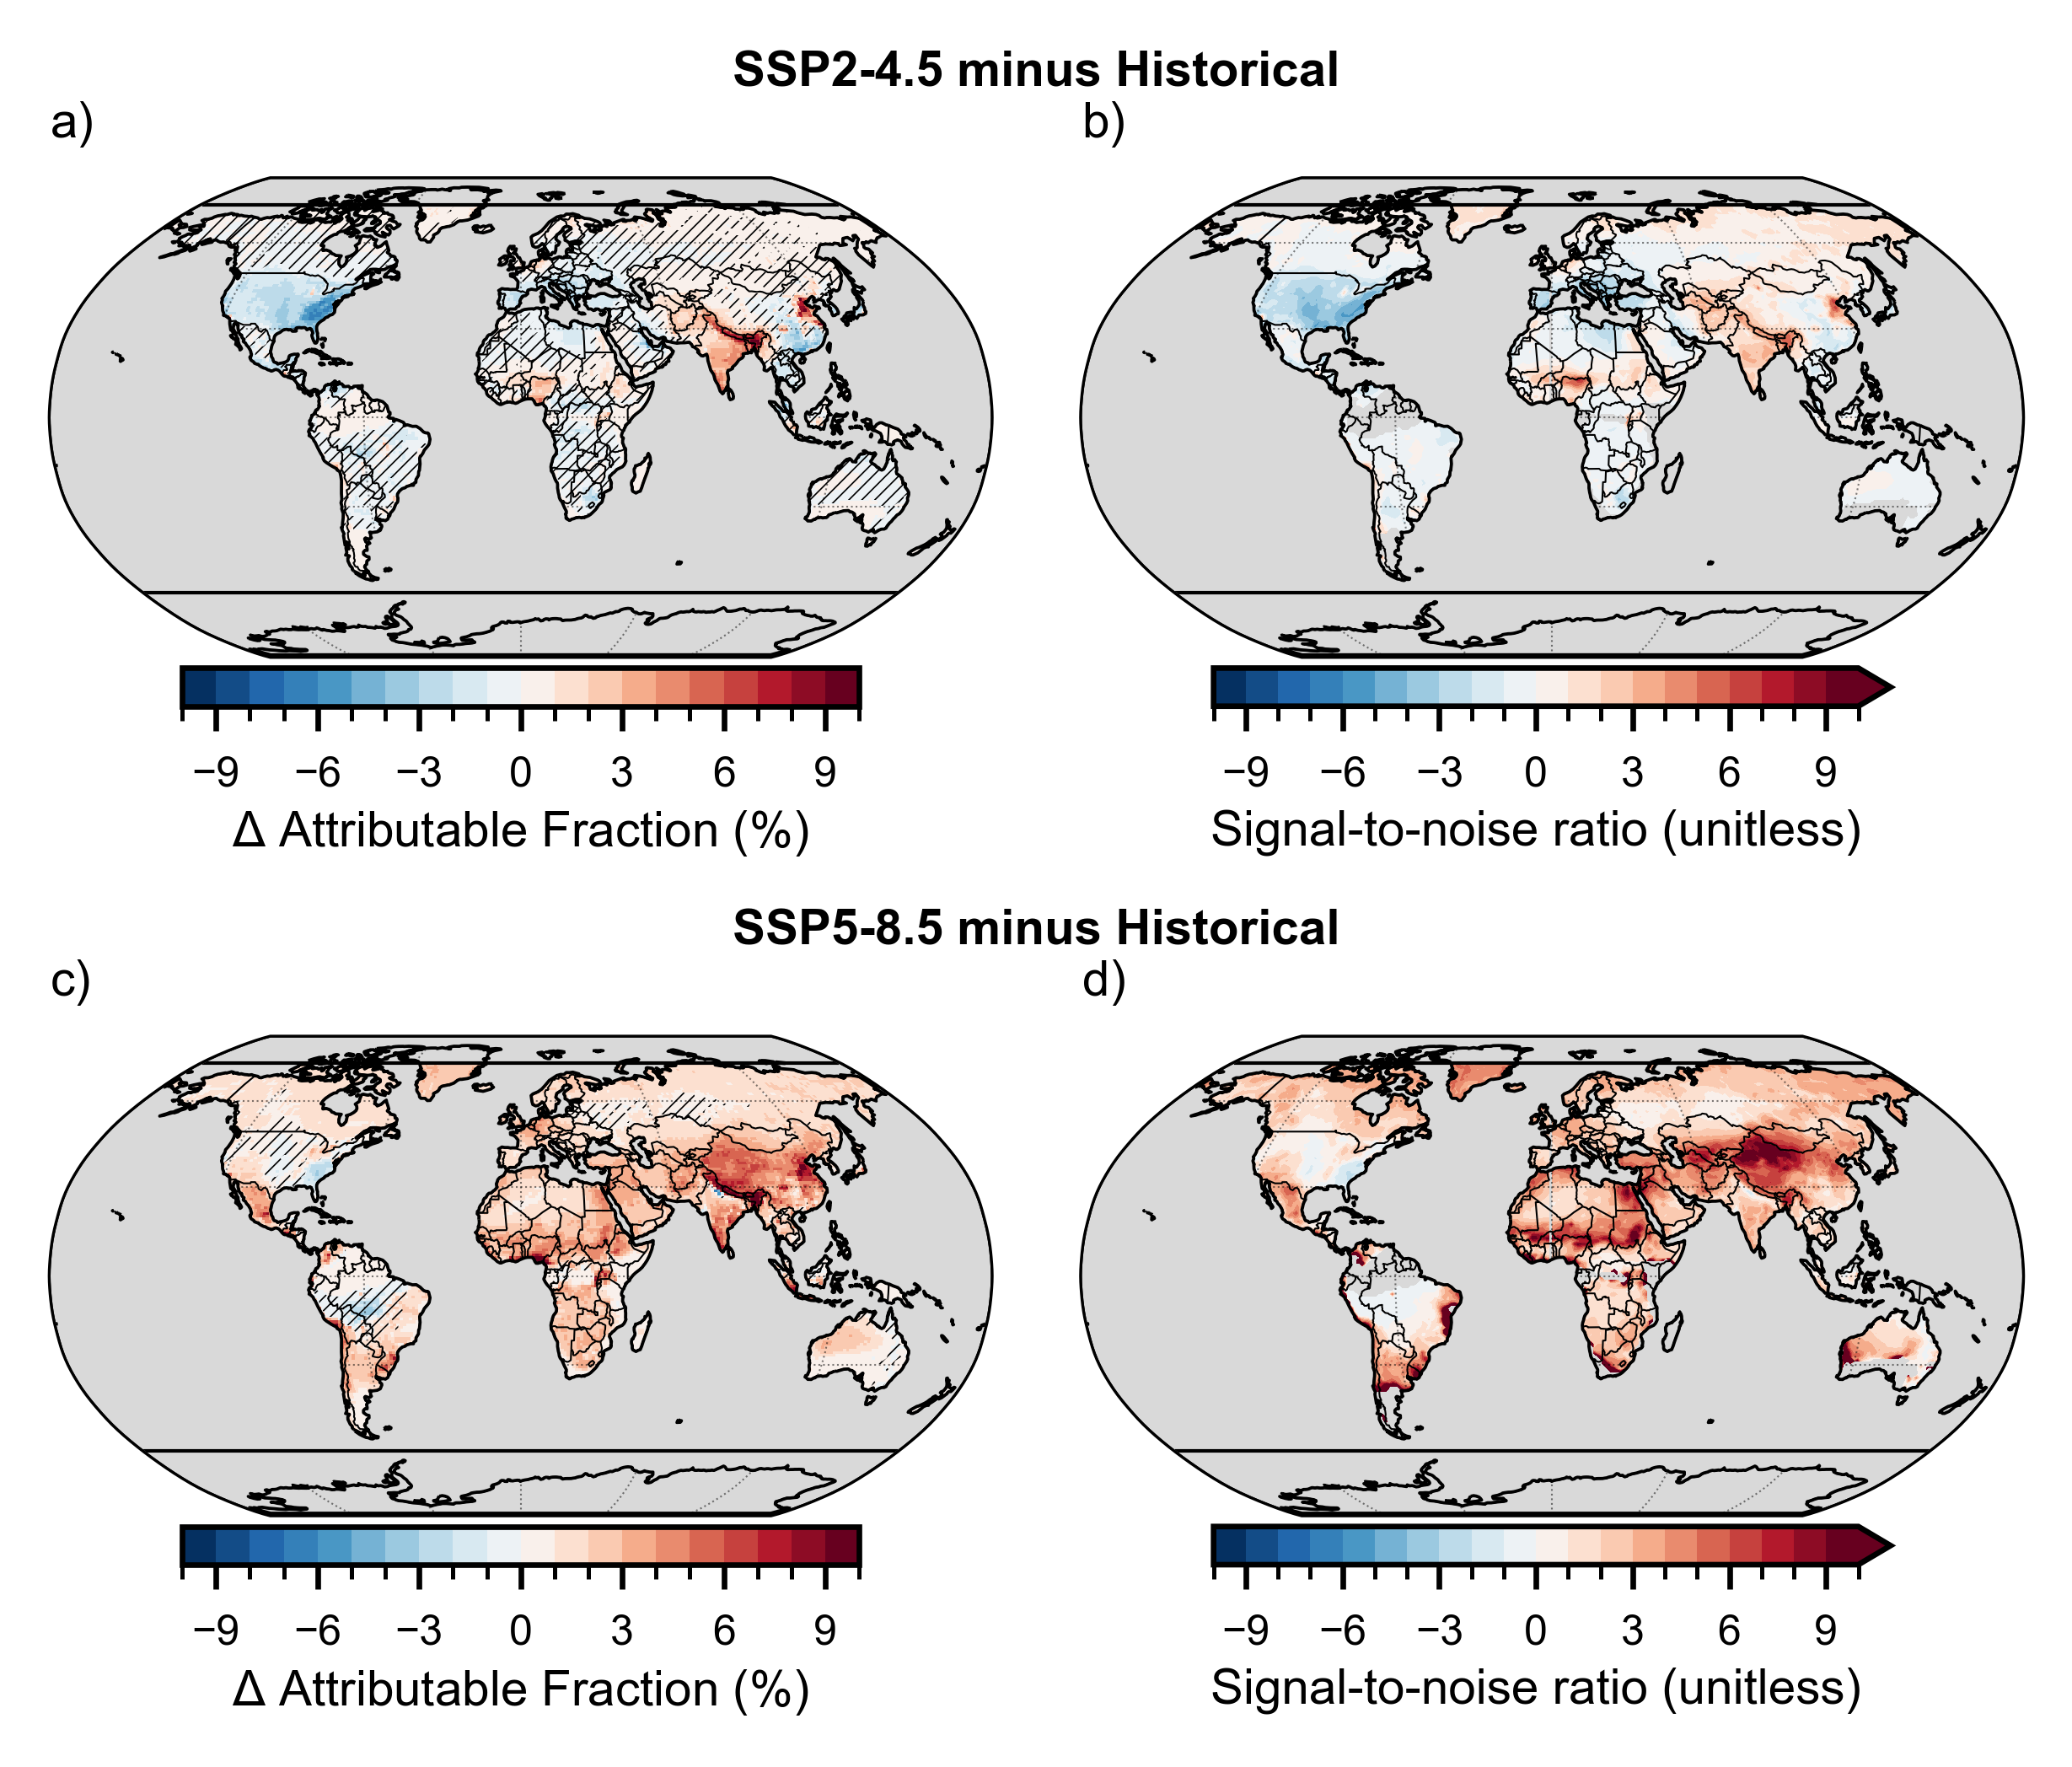

In [14]:
utils.set_matplotlib_font("Arial")

lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()

fig_width_in = 5
fig_height_in = 3.3

fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=600)

gs1 = GridSpec(
    2, 2,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.80, wspace=0.04
)        

proj = ccrs.Robinson(central_longitude=0)

# Row 1
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[0, 1], projection=proj)

# Row 2
ax3 = fig.add_subplot(gs1[1, 0], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

axes = [ax1, ax2, ax3, ax4]

for ax in axes:
    style_map(ax)
    ax.set_facecolor("0.85")
    ax.add_feature(cfeature.LAND, facecolor="0.85", edgecolor="none", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="0.85", edgecolor="none", zorder=0)

########################################################
### Signal ####
vmax = 10
vmin = -vmax
step = 1
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = mpl.colormaps['RdBu_r'] #cm.hawaii_r
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- ssp245 signal --- ##
z1 = ssp245_signal
m1 = z1.plot.pcolormesh(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    add_colorbar=False,
    add_labels=False,
    shading="auto",
)

add_panel_cbar(fig, ax1, m1, label="$\Delta$ Attributable Fraction (%)")
add_snr_hatching(ax1, ssp245_snr, threshold=1.0)

## --- ssp585 signal --- ##
z3 = ssp585_signal
m3 = z3.plot.pcolormesh(
    ax=ax3,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    add_colorbar=False,
    add_labels=False,
    shading="auto",
)

add_panel_cbar(fig, ax3, m3, label="$\Delta$ Attributable Fraction (%)")
add_snr_hatching(ax3, ssp585_snr, threshold=1.0)


##############################################################################
### Signal to Noise ####
vmax = 10
vmin = -vmax
step = 1
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = mpl.colormaps['RdBu_r'] #cm.hawaii_r
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- ssp245 SNR --- ##
z = ssp245_snr

m2 = z.plot.contourf(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

add_panel_cbar(fig, ax2, m2, label="Signal-to-noise ratio (unitless)")

## --- ssp585 AF range --- ##
z = ssp585_snr

m4 = z.plot.contourf(
    ax=ax4,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

add_panel_cbar(fig, ax4, m4, label="Signal-to-noise ratio (unitless)")

##############################################################################
for ax in axes:
    ax.add_feature(
        cfeature.OCEAN,
        facecolor="0.85",
        edgecolor="none",
        zorder=15
    )

    ax.coastlines(linewidth=0.4, color="black", zorder=20)

#######

#for axes in [ax1, ax2, ax3, ax4, ax5, ax6]:
#    plots.clip_to_obs_lat_band(axes, lat_min=-60, lat_max=75)

lons = np.linspace(-180, 180, 361)

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_facecolor("0.85")
    ax.plot(
        lons, np.full_like(lons, 75),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )
    ax.plot(
        lons, np.full_like(lons, -60),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )

# centered row titles
row1_left, row1_right = ax1.get_position(), ax2.get_position()
row2_left, row2_right = ax3.get_position(), ax4.get_position()

x_row1 = 0.5 * (row1_left.x0 + row1_right.x1)
x_row2 = 0.5 * (row2_left.x0 + row2_right.x1)

y_row1 = row1_left.y1 + 0.05
y_row2 = row2_left.y1 + 0.05

fig.text(
    x_row1, y_row1, "SSP2-4.5 minus Historical",
    ha="center", va="bottom", fontsize=7, color="black", fontweight='bold'
)

fig.text(
    x_row2, y_row2, "SSP5-8.5 minus Historical",
    ha="center", va="bottom", fontsize=7, color="black", fontweight='bold'
)

ax1.set_title("a)", loc="left", fontsize=7)
ax2.set_title("b)", loc="left", fontsize=7)

ax3.set_title("c)", loc="left", fontsize=7)
ax4.set_title("d)", loc="left", fontsize=7)


In [23]:
####################################
# Calculation of area-weighted ensemble-mean AF in populated grid cells under each scenario

def calc_fraction_snr(ssp_snr, snr_thres):
    ssp_snr = ssp_snr.to_dataset()
    ssp_snr = utils.add_population_density(ssp_snr)

    mask = ssp_snr["population_density"] > 1

    # populated cells where condition is met
    exceed = mask & (ssp_snr["y_bc_af"] > snr_thres)

    fraction_of_cells = exceed.sum(dim=("lat", "lon")) / mask.sum(dim=("lat", "lon"))

    return fraction_of_cells

snr_thres = 1
frac_ssp245 = calc_fraction_snr(ssp245_snr, snr_thres)
print(f"SSP245 Fraction of Cells with SNR > {snr_thres}")
print(frac_ssp245.values)

snr_thres = 1
frac_ssp585 = calc_fraction_snr(ssp585_snr, snr_thres)
print(f"SSP585 Fraction of Cells with SNR > {snr_thres}")
print(frac_ssp585.values)

snr_thres = 2
frac_ssp245 = calc_fraction_snr(ssp245_snr, snr_thres)
print(f"SSP245 Fraction of Cells with SNR > {snr_thres}")
print(frac_ssp245.values)

snr_thres = 2
frac_ssp585 = calc_fraction_snr(ssp585_snr, snr_thres)
print(f"SSP585 Fraction of Cells with SNR > {snr_thres}")
print(frac_ssp585.values)



SSP245 Fraction of Cells with SNR > 1
0.14297363413971187
SSP585 Fraction of Cells with SNR > 1
0.7174050919633959
SSP245 Fraction of Cells with SNR > 2
0.06378544894445955
SSP585 Fraction of Cells with SNR > 2
0.5267735797771134
